# Multi Drone Mult-Target Tracking

## Setup and Imports

In [1]:
%matplotlib widget

# standard library imports
import sys
import os
import logging
from pathlib import Path
from datetime import datetime
from collections import defaultdict
from typing import List, Tuple

# third-party imports
import numpy as np
from numpy.typing import NDArray
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import display
import tqdm

# Add the project root to the path to ensure imports work correctly
project_root = Path().absolute().parents[1]
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

# Import local modules
from utils import rosbag_utils, df_utils, plotting_utils
import multi_target_tracking as mtt

# Reload imports to ensure the latest code is used
import importlib
importlib.reload(sys.modules['utils'])
importlib.reload(sys.modules['multi_target_tracking'])

# Update references after reload
import utils.df_utils as dfu
import utils.plotting_utils as pu
import utils.rosbag_utils as rbu
import utils.sensor_sim as ss
import multi_target_tracking as mtt

Murty algorithm not available. Please install the murty package when using MHT tracking.


In [2]:
# plotting font sizes
pu.plt.rcParams.update({'font.size': 16,
                        'axes.labelsize': 16,
                        'axes.titlesize': 16,
                        'xtick.labelsize': 16,
                        'ytick.labelsize': 16,
                        'legend.fontsize': 16,
                        'figure.titlesize': 24})

## Configuration and Data Loading

Set up the paths and load the rosbag file with projection data from multiple drones.

In [3]:
## CONFIGURATION
BAG_PATH = os.path.join(project_root, 'data/2_zebras_3_drones_gps_drift.bag')
script_name = "06_multi_drone_MTT"
LOG_DIR = os.path.join(project_root, f'logs/{script_name}')
RESULTS_DIR = os.path.join(project_root, f'results/{script_name}')
PLOTS_DIR = os.path.join(RESULTS_DIR, "plots")
# Create directories if they don't exist
os.makedirs(LOG_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(PLOTS_DIR, exist_ok=True)

## LOGGING CONFIGURATION
# Configure logging to output to both console and file
log_file = LOG_DIR + f"/{script_name}_{datetime.now().strftime('%Y%m%d_%H%M%S')}.log"
# Create logger
logger = logging.getLogger()
logger.setLevel(logging.INFO)
# Clear any existing handlers
for handler in logger.handlers[:]: 
    logger.removeHandler(handler)
# Create file handler
file_handler = logging.FileHandler(log_file)
file_handler.setLevel(logging.DEBUG)
file_format = logging.Formatter('%(asctime)s - %(name)s - %(levelname)s - %(message)s')
file_handler.setFormatter(file_format)
# Create console handler
console_handler = logging.StreamHandler()
console_handler.setLevel(logging.INFO)
console_format = logging.Formatter('%(levelname)s: %(message)s')
console_handler.setFormatter(console_format)
# Add handlers to logger
logger.addHandler(file_handler)
logger.addHandler(console_handler)

# Log to file and console
logger.info("Notebook started - Testing Multi-Target Multi-Drone Tracking")

## ROSBAG READER
# Load the bag file
bag_path = Path(BAG_PATH)
if not bag_path.exists():
    raise FileNotFoundError(f"Rosbag file not found: {bag_path}")
bag_reader = rbu.load_rosbag(bag_path)
rbu.display_rosbag_info(bag_reader)

INFO: Notebook started - Testing Multi-Target Multi-Drone Tracking


#################### Topics and message counts: ####################
Topic: /gazebo/model_states
    Message type: TopicInfo(msgtype='gazebo_msgs/msg/ModelStates', msgdef=MessageDefinition(format=<MessageDefinitionFormat.MSG: 1>, data='# broadcast all model states in world frame\nstring[] name                 # model names\ngeometry_msgs/Pose[] pose     # desired pose in world frame\ngeometry_msgs/Twist[] twist   # desired twist in world frame\n\n================================================================================\nMSG: geometry_msgs/Pose\n# A representation of pose in free space, composed of position and orientation. \nPoint position\nQuaternion orientation\n\n================================================================================\nMSG: geometry_msgs/Point\n# This contains the position of a point in free space\nfloat64 x\nfloat64 y\nfloat64 z\n\n================================================================================\nMSG: geometry_msgs/Quaternion\n# This 

## Data Extraction and Processing

Extract projection data and ground truth from multiple drones for comparison.

In [4]:
## DATA EXTRACTION
# Define topics to analyze for multiple drones
topics = [
    # Ground truth data
    "/machine_1/target_tracker/MTT/GT/target0",
    "/machine_1/target_tracker/MTT/GT/target2",
    # Projected detections from all drones
    "/machine_1/object_detections/projected_to_world",
    "/machine_2/object_detections/projected_to_world",
    "/machine_3/object_detections/projected_to_world",
]

# Extract and process data
topic_data = {}
for topic in topics:
    data = rbu.create_df_from_bag(bag_reader, topic)
    topic_data[topic] = data
    logger.info(f"Extracted {len(data)} entries from {topic}")

INFO: Processing topic: '/machine_1/target_tracker/MTT/GT/target0' with message type: 'geometry_msgs/msg/PoseWithCovarianceStamped'
INFO: Extracted 26743 entries from /machine_1/target_tracker/MTT/GT/target0
INFO: Processing topic: '/machine_1/target_tracker/MTT/GT/target2' with message type: 'geometry_msgs/msg/PoseWithCovarianceStamped'
INFO: Extracted 26916 entries from /machine_1/target_tracker/MTT/GT/target2
INFO: Processing topic: '/machine_1/object_detections/projected_to_world' with message type: 'geometry_msgs/msg/PoseWithCovarianceStamped'
INFO: Extracted 737 entries from /machine_1/object_detections/projected_to_world
INFO: Processing topic: '/machine_2/object_detections/projected_to_world' with message type: 'geometry_msgs/msg/PoseWithCovarianceStamped'
INFO: Extracted 823 entries from /machine_2/object_detections/projected_to_world
INFO: Processing topic: '/machine_3/object_detections/projected_to_world' with message type: 'geometry_msgs/msg/PoseWithCovarianceStamped'
INFO:

In [5]:
import copy

## PROCESS DATA FOR TRACKING BASED ON PROJECTED OBJECT DETECTIONS FROM MULTIPLE DRONES
proj_topics = [
    "/machine_1/object_detections/projected_to_world_array",
    "/machine_2/object_detections/projected_to_world_array",
    "/machine_3/object_detections/projected_to_world_array",
]

projected_arrays = []
projected_arrays_df = []
all_proj_detections = []

for topic in proj_topics:
    projected_array = rbu.import_detections_array_data(bag_reader, topic)
    # append to list
    projected_arrays.append(projected_array)
    all_proj_detections.extend(projected_array)
    
    # Convert to DataFrame
    time = []
    meas = []
    for timestamp, measurements, drone_id in projected_array:
        for measurement in measurements:
            time.append(timestamp)
            meas.append(measurement)
    time = np.array(time)
    meas = np.array(meas)
    # append to list
    projected_arrays_df.append(dfu.measurements_to_dataframe(meas, time))

# Sort detections by time
all_proj_detections.sort(key=lambda x: x[0])

# simulate OOSMs
oosm_percentage = 0.1  # 10% OOSMs
proj_detections_oosm = copy.deepcopy(all_proj_detections)
meas_moved = []
for idx, (time, meas, drone_id) in enumerate(all_proj_detections):
    move_by = 0
    if np.random.rand() < oosm_percentage:
        move_by = np.random.randint(1, 7)
        # Remove the element from that index
        element = proj_detections_oosm.pop(idx)
        # Insert it at the new index (but not below 0)
        new_index = max(0, idx - move_by)
        proj_detections_oosm.insert(new_index, element)
    meas_moved.append(move_by)

INFO: Importing detections array data from topics: /machine_1/object_detections/projected_to_world_array
INFO: Importing detections array data from topics: /machine_2/object_detections/projected_to_world_array
INFO: Importing detections array data from topics: /machine_3/object_detections/projected_to_world_array


INFO: Topic: /machine_1/object_detections/projected_to_world_array
INFO: Topic: /machine_2/object_detections/projected_to_world_array
INFO: Topic: /machine_3/object_detections/projected_to_world_array


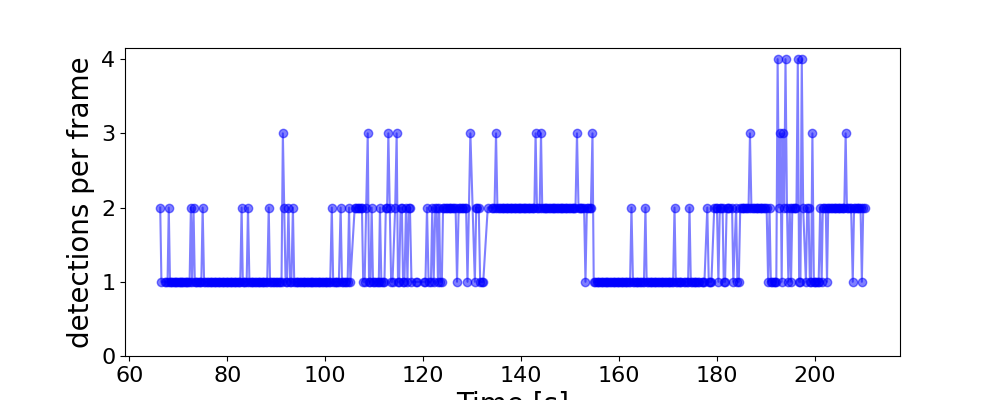

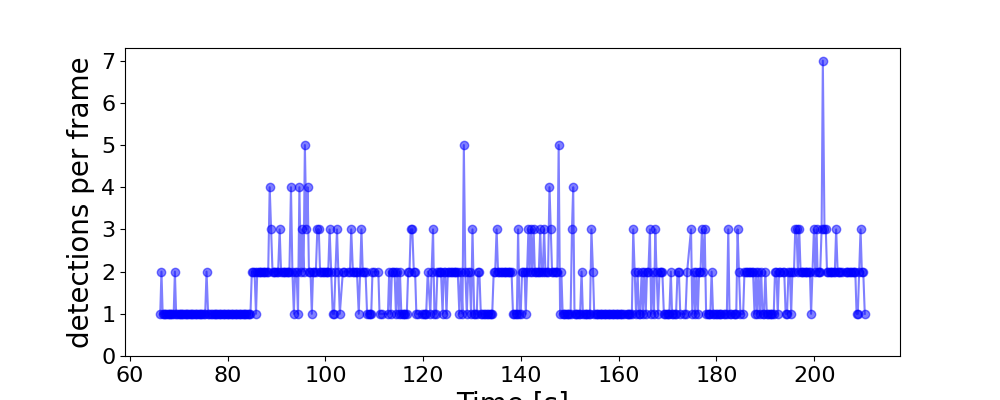

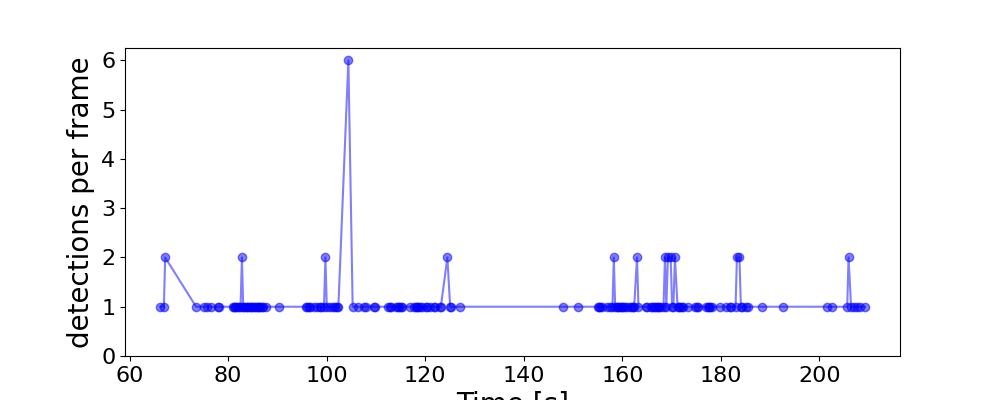

In [6]:
for projected_array, topic in zip(projected_arrays, proj_topics):
    logger.info(f"Topic: {topic}")
    # get number of detections per frame
    num_detections = [len(meas) for _, meas, _ in projected_array]
    timestamps = [t for t, _, _ in projected_array]
    # Plot the number of detections per frame
    plt.figure(figsize=(10, 4))
    plt.plot(timestamps, num_detections, marker='o', linestyle='-', color='b', alpha=0.5)
    # plt.title("Number of Detections per Frame", fontsize=24)
    plt.xlabel("Time [s]", fontsize=20)
    plt.ylabel("detections per frame", fontsize=20)

    # Set integer ticks on y-axis
    max_y = max(num_detections) + 1
    y_ticks = np.arange(0, max_y, 1, dtype=int)
    plt.yticks(y_ticks)

    plt.savefig(os.path.join(PLOTS_DIR, f"projected_meas_{topic.split('/')[1]}.svg"), dpi=600, bbox_inches='tight')


In [7]:
def group_measurements(
        timestaps: List[float], 
        measurements: NDArray[np.object_], 
        drone_id: int
        ) -> List[Tuple[float, NDArray[np.object_], int]]:
    measurements_by_time = defaultdict(list)
    for time, meas in zip(timestaps, measurements):
        rounded_time = round(time * 100) / 100
        measurements_by_time[rounded_time].append(meas)
    
    data = []
    for time in sorted(measurements_by_time.keys()):
        meas = np.array(measurements_by_time[time])
        data.append((time, meas, drone_id))
    return data   

In [8]:
import copy

## CREATE DATA WITH IDs BASED ON GROUND TRUTH
# downsample gt data
rate = 0.4  # Sample rate in seconds
measurements_target0 = dfu.sample_data(
    topic_data["/machine_1/target_tracker/MTT/GT/target0"],
    sample_rate=rate,
    )
measurements_target2 = dfu.sample_data(
    topic_data["/machine_1/target_tracker/MTT/GT/target2"],
    sample_rate=rate,
    )

zebra_measurements = [measurements_target0, measurements_target2]

# for reference compare number of projected detections and simulated detections
print(f"Number of projected detections: {len(topic_data['/machine_1/object_detections/projected_to_world'])}")
print(f"Number of simulated detections: {len(measurements_target0) + len(measurements_target2)}")

# parameters for simulation
white_noise_std = [0.5]*3
random_walk = True  # Enable random walk
bounds = [1]*3  # Bounds for random walk
outliers = 0.04  # 4% outliers
outlier_std = [50, 50, 10]  # Outlier standard deviation

# create simulated zebra database
zebra_db, zebra_ids = ss.create_zebra_db(
    zebras_in_db=10, 
    zebras_in_gt=2, 
)

# Simulate ID measurements
id_detections = [] # grouped detections for each drone
id_data = {}

# Parameters for ID simulation
id_mean = 0.5
id_std = 0.2
id_outlier = 0.1

# (1-3) simulate measurements
for i in range(1, 4):
    id_meas = []
    id_time = []
    for meas in zebra_measurements:
        time, measurements = ss.simulate_position_sensor(
            meas, 
            white_noise_std=white_noise_std,
            random_walk=random_walk, 
            bounds=bounds,
            outlier_percentage=outliers, 
            outlier_std=outlier_std
        )
        id_time.append(time)
        id_meas.append(measurements)

    # Simulate ID measurements
    id_meas = ss.simulate_zebra_identification(
        zebra_trajectories=id_meas,
        zebra_ids_db=zebra_db,
        zebra_ids_meas=zebra_ids,
        mean_confidence=id_mean,
        confidence_std=id_std,
        outlier_percentage=id_outlier,
    )

    id_data[f"drone_{i}"] = (id_time, id_meas)

    # Add to the combined id_detections list
    meas = group_measurements(
        np.concatenate(id_time), 
        np.concatenate(id_meas), 
        i,  # Drone ID
    )
    id_detections.extend(meas)

# Sort detections by time
id_detections.sort(key=lambda x: x[0])

# simulate OOSMs
oosm_percentage = 0.1  # 10% OOSMs
id_detections_oosm = copy.deepcopy(id_detections)
meas_moved = []
for idx, (time, meas, drone_id) in enumerate(id_detections):
    move_by = 0
    if np.random.rand() < oosm_percentage:
        move_by = np.random.randint(1, 7)
        # Remove the element from that index
        element = id_detections_oosm.pop(idx)
        # Insert it at the new index (but not below 0)
        new_index = max(0, idx - move_by)
        id_detections_oosm.insert(new_index, element)
    meas_moved.append(move_by)
        

# Arrays for dataframes
id_meas_df = {}
# Convert measurements to DataFrame for visualization
for drone_id, (id_time, id_meas) in id_data.items():
    id_meas_df[drone_id] = []
    for time, meas in zip(id_time, id_meas):
        time = np.array(time)
        meas = np.array(meas)
        id_meas_df[drone_id].append(dfu.measurements_to_dataframe(meas, time))

Number of projected detections: 737
Number of simulated detections: 726


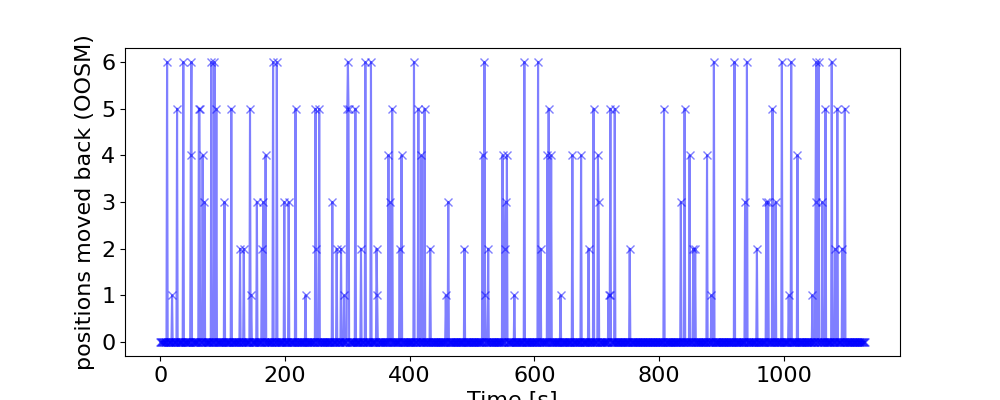

In [9]:
# Plot how much a measurement was moved back
plt.figure(figsize=(10, 4))
plt.plot(range(len(meas_moved)), meas_moved, marker='x', linestyle='-', color='b', alpha=0.5)
# plt.title("Number of Detections per Frame", fontsize=24)
plt.xlabel("Time [s]")
plt.ylabel("positions moved back (OOSM)")

# Set integer ticks on y-axis
max_y = max(num_detections) + 1
y_ticks = np.arange(0, max_y, 1, dtype=int)
plt.yticks(y_ticks)
plt.show()

## Multi-Drone Tracking

### TEST 1: Tracker using projected measurements

#### Tracker

In [10]:
gater = mtt.MahalanobisGater()
likelihood = mtt.MahalanobisLikelihood()
filter = mtt.KFTrack()
score_logic = mtt.ScoreLogic()
mn_logic = mtt.MNLogic()

tracker = mtt.JPDATracker(
    filter_obj=filter,
    gater=gater,
    likelihood=likelihood,
    track_logic=mn_logic,
    drone_id=None,  # No specific drone ID for multi-drone processing
    )
proj_tracker = mtt.SynchronizedDistributedTracker(tracker, 3)

logger.info("Starting tracking using multi-drone projected measurements")
# Evaluate the tracker using the grouped measurements with identifications
for (time, measurements, drone_id) in tqdm.tqdm(all_proj_detections, total=len(all_proj_detections), desc="Multi-Drone Proj Tracking"):
    proj_tracker.add_measurements(time, measurements, drone_id)
multi_drone_proj_results = proj_tracker.tracks
print(f"Number of tracks from multi-drone projected data: {len(multi_drone_proj_results)}")

INFO: Starting tracking using multi-drone projected measurements
Multi-Drone Proj Tracking:   0%|          | 0/1150 [00:00<?, ?it/s]INFO: Wait limit exceeded. Processing data without all drones. 
INFO: Wait limit exceeded. Processing data without all drones. 
INFO: Wait limit exceeded. Processing data without all drones. 
INFO: Wait limit exceeded. Processing data without all drones. 
Multi-Drone Proj Tracking:   1%|▏         | 15/1150 [00:00<00:09, 124.96it/s]INFO: Wait limit exceeded. Processing data without all drones. 
INFO: Wait limit exceeded. Processing data without all drones. 
INFO: Wait limit exceeded. Processing data without all drones. 
INFO: Wait limit exceeded. Processing data without all drones. 
INFO: Wait limit exceeded. Processing data without all drones. 
INFO: Wait limit exceeded. Processing data without all drones. 
INFO: Wait limit exceeded. Processing data without all drones. 
INFO: Wait limit exceeded. Processing data without all drones. 
INFO: Wait limit exceed

Number of tracks from multi-drone projected data: 11


In [11]:
# Filter for confirmed tracks from ID-based tracking
confirmed_proj_tracks = [track for track in multi_drone_proj_results if track.stage == mtt.TrackStage.CONFIRMED or track.stage == mtt.TrackStage.ARCHIVED]
print("\n############### MULTI-DRONE PROJ TRACKS ###############")
# for track in confirmed_proj_tracks:
#     print(f"Track ID: {track.id}, Stage: {track.stage}, Length: {len(track.timestamp_history)}")
#     print(f"Track Score: {track.score}")

print(f"Number of confirmed Proj tracks: {len(confirmed_proj_tracks)}")

proj_results_df = [dfu.track_to_dataframe(track) for track in confirmed_proj_tracks]


############### MULTI-DRONE PROJ TRACKS ###############
Number of confirmed Proj tracks: 7


#### Plots

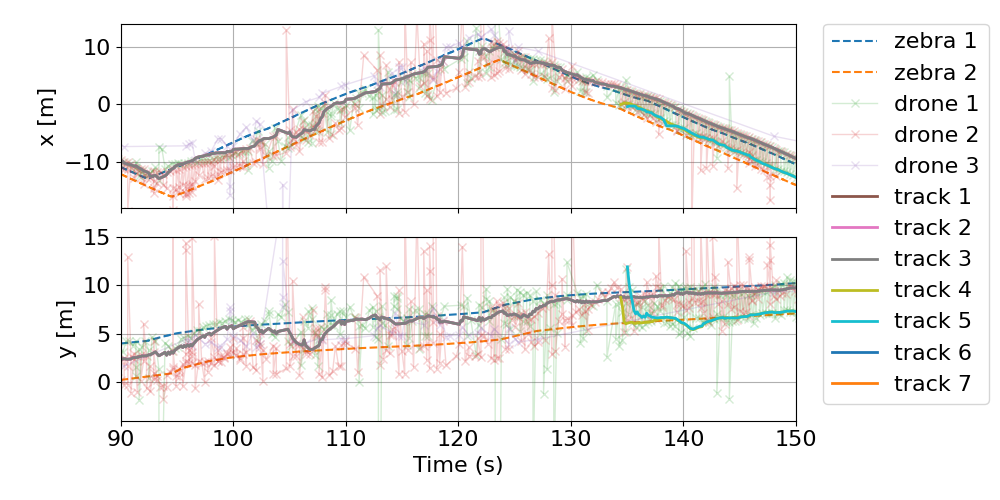

In [12]:
coords = ['x', 'y']
## Multi-drone position tracker plot with GT and measurements
fig_proj = pu.plot_xyz_over_time(topic_data["/machine_1/target_tracker/MTT/GT/target0"], label="zebra 1", linestyle='--', linewidth=1.5, coords=coords)
pu.plot_xyz_over_time(topic_data["/machine_1/target_tracker/MTT/GT/target2"], fig=fig_proj, label="zebra 2", linestyle='--', linewidth=1.5, coords=coords)

# plot projected detections from all drones
for i, projected_df in enumerate(projected_arrays_df):
    pu.plot_xyz_over_time(projected_df, fig=fig_proj, label=f"drone {i+1}", coords=coords, marker='x', alpha=0.2)

# Plot tracks
for i, track_df in enumerate(proj_results_df):
    pu.plot_xyz_over_time(track_df, fig=fig_proj, label=f"track {i+1}", coords=coords, linewidth=2.0)

handles, labels = fig_proj.axes[0].get_legend_handles_labels()
fig_proj.legend(handles, labels, loc='upper right', bbox_to_anchor=(1, 0.975))
fig_proj.set_size_inches(10,5)
fig_proj.tight_layout(rect=[0, 0, 0.82, 1.0])
fig_proj.axes[0].set_ylim((-18, 14))
fig_proj.axes[1].set_ylim((-4, 15))
for ax in fig_proj.axes:
    ax.set_xlim((90, 150))
plt.show()

In [13]:
# fig_proj.savefig(os.path.join(PLOTS_DIR, f"multi_drone_proj_tracking.svg"), dpi=600, bbox_inches='tight')

### Test 2: Using simulated position measurements

#### Tracker

In [14]:
gater = mtt.MahalanobisGater()
likelihood = mtt.MahalanobisLikelihood()
filter = mtt.KFTrack()
score_logic = mtt.ScoreLogic()
mn_logic = mtt.MNLogic()

pos_tracker = mtt.DistributedJPDA(
    filter_obj=filter,
    gater=gater,
    likelihood=likelihood,
    track_logic=mn_logic,
    drone_id=None,  # No specific drone ID for multi-drone processing
    )

logger.info("Starting tracking using multi-drone projected measurements")
# Evaluate the tracker using the grouped measurements with identifications
for (time, measurements, drone_id) in tqdm.tqdm(id_detections_oosm, total=len(id_detections_oosm), desc="Multi-Drone Proj Tracking"):
    pos_tracker.add_measurements(time, measurements, drone_id)
multi_drone_pos_results = pos_tracker.tracks
print(f"Number of tracks from multi-drone projected data: {len(multi_drone_pos_results)}")

INFO: Starting tracking using multi-drone projected measurements
Multi-Drone Proj Tracking:   0%|          | 0/1131 [00:00<?, ?it/s]

Multi-Drone Proj Tracking: 100%|██████████| 1131/1131 [00:13<00:00, 81.54it/s] 

Number of tracks from multi-drone projected data: 7


In [15]:
# Filter for confirmed tracks from ID-based tracking
confirmed_pos_tracks = [track for track in multi_drone_pos_results if track.stage == mtt.TrackStage.CONFIRMED or track.stage == mtt.TrackStage.ARCHIVED]
print("\n############### MULTI-DRONE PROJ TRACKS ###############")
# for track in confirmed_pos_tracks:
#     print(f"Track ID: {track.id}, Stage: {track.stage}, Length: {len(track.timestamp_history)}")
#     print(f"Track Score: {track.score}")

print(f"Number of confirmed Proj tracks: {len(confirmed_pos_tracks)}")

pos_results_df = [dfu.track_to_dataframe(track) for track in confirmed_pos_tracks]


############### MULTI-DRONE PROJ TRACKS ###############
Number of confirmed Proj tracks: 0


#### Plots

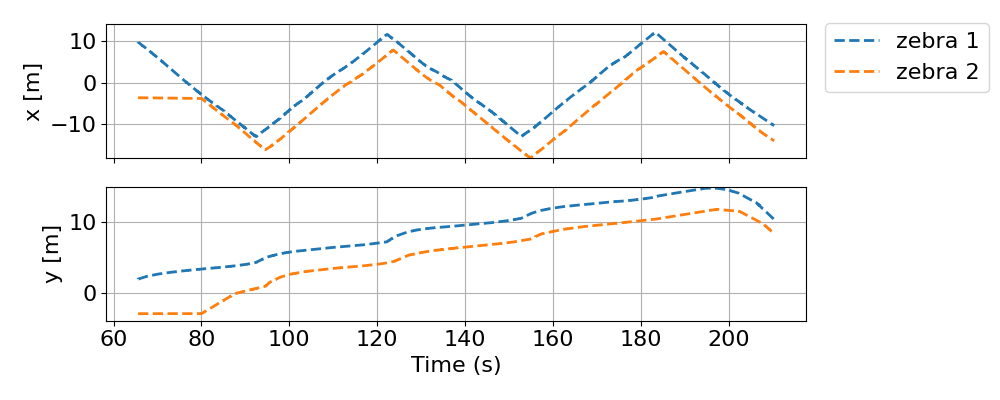

In [16]:
coords = ['x', 'y']
## Multi-drone position tracker plot with GT and measurements
fig_multi = pu.plot_xyz_over_time(topic_data["/machine_1/target_tracker/MTT/GT/target0"], label="zebra 1", linestyle='--', linewidth=2, coords=coords)
pu.plot_xyz_over_time(topic_data["/machine_1/target_tracker/MTT/GT/target2"], fig=fig_multi, label="zebra 2", linestyle='--', linewidth=2, coords=coords)

# Plot tracks
for i, track_df in enumerate(pos_results_df):
    pu.plot_xyz_over_time(track_df, fig=fig_multi, label=f"track {i+1}", coords=coords)

handles, labels = fig_multi.axes[0].get_legend_handles_labels()
fig_multi.legend(handles, labels, loc='upper right', bbox_to_anchor=(1, 0.97))
fig_multi.set_size_inches(10,4)
fig_multi.tight_layout(rect=[0, 0, 0.83, 1.0])
fig_multi.axes[0].set_ylim((-18, 14))
fig_multi.axes[1].set_ylim((-4, 15))
# for ax in fig_multi.axes:
#     ax.set_xlim((65, 200))
plt.show()

In [17]:
# fig_multi.savefig(os.path.join(PLOTS_DIR, f"reprocessing_gate1.5_wn0.5_big.svg"), dpi=600, bbox_inches='tight')

In [18]:
# pickle the results
# for i, track_df in enumerate(proj_results_df):
#     track_df.to_pickle(os.path.join(RESULTS_DIR, f"multi_proj_gate1.5_wn0.5_rw1.0_tracks_{i}.pkl"))

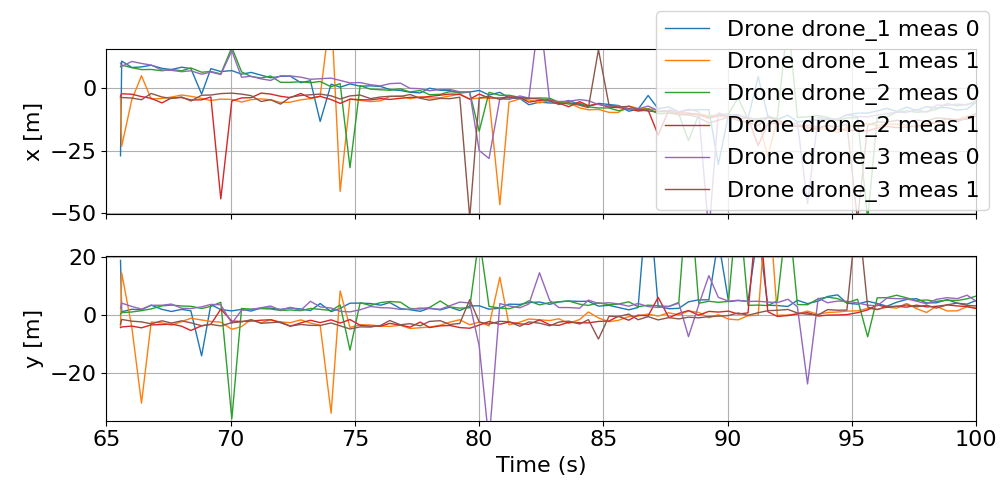

In [19]:
# plot the measurements
for drone_idx, (key, df_list) in enumerate(id_meas_df.items()):
    if drone_idx == 0:
        fig_meas = pu.plot_xyz_over_time(df_list[0], label=f"Drone {key} meas 0", coords=coords, noisy_limits=True)
        pu.plot_xyz_over_time(df_list[1], fig=fig_meas, label=f"Drone {key} meas 1", coords=coords, noisy_limits=True)
    else:
        for i, df in enumerate(df_list):
            pu.plot_xyz_over_time(df, fig=fig_meas, label=f"Drone {key} meas {i}", coords=coords, noisy_limits=True)

handles, labels = fig_meas.axes[0].get_legend_handles_labels()
fig_meas.legend(handles, labels, loc='upper right')
fig_meas.tight_layout(rect=[0, 0, 1, 0.95])
for ax in fig_meas.axes:
    ax.set_xlim((65, 100))
plt.show()

### TEST 2: Tracker using simulated ID measurements from multiple drones

In [20]:
id_gater = mtt.IDGater()
id_likelihood = mtt.IdLikelihood()
filter = mtt.KFTrack()
score_logic = mtt.ScoreLogic()
mn_logic = mtt.MNLogic()

id_tracker = mtt.DistributedJPDA(
    filter_obj=filter,
    gater=id_gater,
    likelihood=id_likelihood,
    track_logic=mn_logic,
    drone_id=None,  # No specific drone ID for multi-drone processing
    )

logger.info("Starting tracking using multi-drone ID measurements")
# Evaluate the tracker using the grouped measurements with identifications
for (time, measurements, drone_id) in tqdm.tqdm(id_detections_oosm, total=len(id_detections_oosm), desc="Multi-Drone ID Tracking"):
    id_tracker.add_measurements(time, measurements, drone_id)
multi_drone_id_results = id_tracker.tracks
print(f"Number of tracks from multi-drone ID data: {len(multi_drone_id_results)}")

INFO: Starting tracking using multi-drone ID measurements
Multi-Drone ID Tracking: 100%|██████████| 1131/1131 [00:08<00:00, 131.99it/s]

Number of tracks from multi-drone ID data: 8


In [21]:
# Filter for confirmed tracks from ID-based tracking
confirmed_id_tracks = [track for track in multi_drone_id_results if track.stage == mtt.TrackStage.CONFIRMED or track.stage == mtt.TrackStage.ARCHIVED]
print("\n############### MULTI-DRONE ID TRACKS ###############")
# for track in confirmed_id_tracks:
#     print(f"Track ID: {track.id}, Stage: {track.stage}, Length: {len(track.timestamp_history)}")
#     print(f"Track Score: {track.score}")

print(f"Number of confirmed ID tracks: {len(confirmed_id_tracks)}")

id_results_df = [dfu.track_to_dataframe(track) for track in confirmed_id_tracks]


############### MULTI-DRONE ID TRACKS ###############
Number of confirmed ID tracks: 1


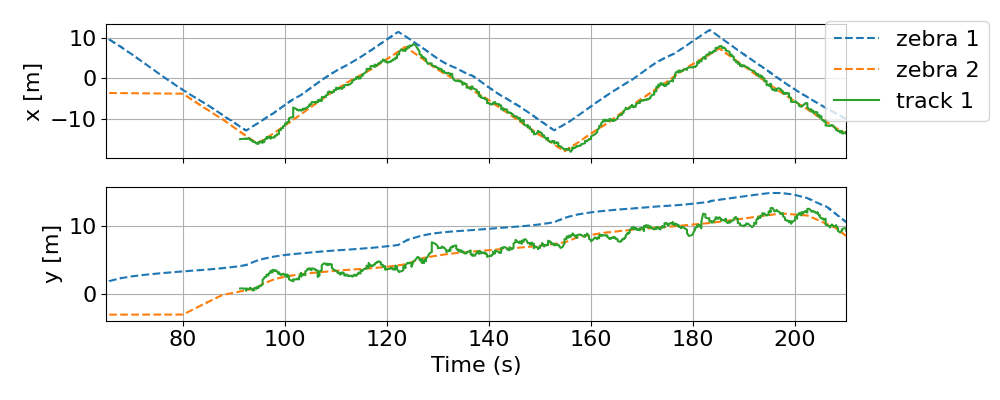

In [22]:
coords = ['x', 'y']
## ID tracker plot with GT
fig_id_gt = pu.plot_xyz_over_time(topic_data["/machine_1/target_tracker/MTT/GT/target0"], label="zebra 1", coords=coords, linestyle='--', linewidth=1.5)
pu.plot_xyz_over_time(topic_data["/machine_1/target_tracker/MTT/GT/target2"], fig=fig_id_gt, label="zebra 2", coords=coords, linestyle='--', linewidth=1.5)

# # Plot ID-based tracks
for i, track_df in enumerate(id_results_df):
    pu.plot_xyz_over_time(track_df, fig=fig_id_gt, label=f"track {i+1}", coords=coords, linewidth=1.5)

handles, labels = fig_id_gt.axes[0].get_legend_handles_labels()
fig_id_gt.legend(handles, labels, loc='upper right', bbox_to_anchor=(1, 0.975))
fig_id_gt.set_size_inches(10,4)
fig_id_gt.tight_layout(rect=[0, 0, 0.87, 1.0])
for ax in fig_id_gt.axes:
    ax.set_xlim((65, 210))
plt.show()

In [23]:
# fig_id_gt.savefig(os.path.join(PLOTS_DIR, f"id_gate0.1_mean0.3_std0.2_outlier_0.1.svg"), dpi=600, bbox_inches='tight')

### Buffering approach with simulated position measurements

#### Tracker

In [24]:
gater = mtt.MahalanobisGater()
likelihood = mtt.MahalanobisLikelihood()
filter = mtt.KFTrack()
score_logic = mtt.ScoreLogic()
mn_logic = mtt.MNLogic()

tracker = mtt.JPDATracker(
    filter_obj=filter,
    gater=gater,
    likelihood=likelihood,
    track_logic=mn_logic,
    drone_id=None,  # No specific drone ID for multi-drone processing
    )
buffering_tracker = mtt.SynchronizedDistributedTracker(tracker, 3)

logger.info("Starting tracking using multi-drone projected measurements")
# Evaluate the tracker using the grouped measurements with identifications
for (time, measurements, drone_id) in tqdm.tqdm(id_detections_oosm, total=len(id_detections_oosm), desc="Multi-Drone Proj Tracking"):
    buffering_tracker.add_measurements(time, measurements, drone_id)
multi_drone_results = buffering_tracker.tracks
print(f"Number of tracks from multi-drone projected data: {len(multi_drone_results)}")

INFO: Starting tracking using multi-drone projected measurements
Multi-Drone Proj Tracking:   0%|          | 0/1131 [00:00<?, ?it/s]INFO: Wait limit exceeded. Processing data without all drones. 


INFO: Wait limit exceeded. Processing data without all drones. 
Multi-Drone Proj Tracking:   1%|          | 13/1131 [00:00<00:08, 129.50it/s]INFO: Wait limit exceeded. Processing data without all drones. 
C:\Users\jonas\Documents\Studium\Master\Masterarbeit\Abgabe\mtt_testing_framework\src\multi_target_tracking\gaters\mahalanobis_gater.py:80: RuntimeWarning: invalid value encountered in sqrt
  mahalanobis_distance = np.sqrt(float(diff.T @ inv_cov @ diff))
INFO: Wait limit exceeded. Processing data without all drones. 
Multi-Drone Proj Tracking:   3%|▎         | 35/1131 [00:00<00:06, 181.01it/s]INFO: Wait limit exceeded. Processing data without all drones. 
INFO: Wait limit exceeded. Processing data without all drones. 
INFO: Wait limit exceeded. Processing data without all drones. 
Multi-Drone Proj Tracking:   5%|▌         | 57/1131 [00:00<00:05, 192.11it/s]INFO: Wait limit exceeded. Processing data without all drones. 
INFO: Wait limit exceeded. Processing data without all drones. 
IN

Number of tracks from multi-drone projected data: 7


In [25]:
# Filter for confirmed tracks from ID-based tracking
confirmed_tracks = [track for track in multi_drone_results if track.stage == mtt.TrackStage.CONFIRMED or track.stage == mtt.TrackStage.ARCHIVED]
print("\n############### MULTI-DRONE Buffering TRACKS ###############")
# for track in confirmed_tracks:
#     print(f"Track ID: {track.id}, Stage: {track.stage}, Length: {len(track.timestamp_history)}")
#     print(f"Track Score: {track.score}")

print(f"Number of confirmed ID tracks: {len(confirmed_tracks)}")

results_df = [dfu.track_to_dataframe(track) for track in confirmed_tracks]


############### MULTI-DRONE Buffering TRACKS ###############
Number of confirmed ID tracks: 0


#### Plots

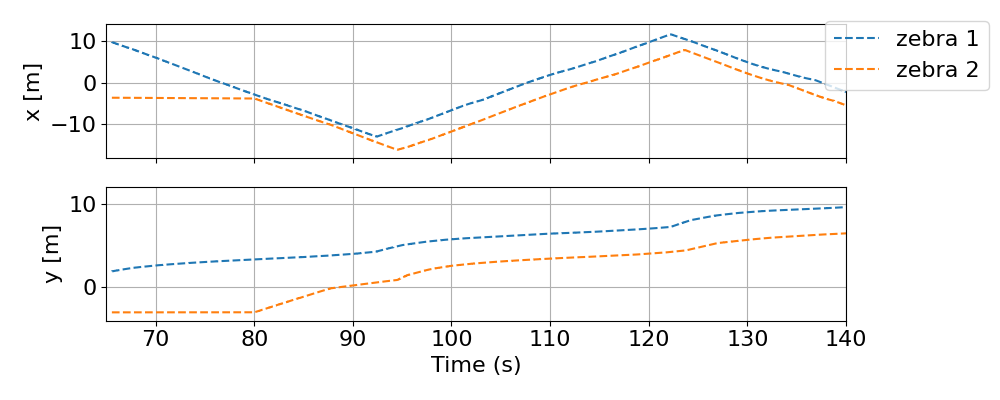

In [26]:
coords = ['x', 'y']
## ID tracker plot with GT
fig_syn = pu.plot_xyz_over_time(topic_data["/machine_1/target_tracker/MTT/GT/target0"], label="zebra 1", coords=coords, linestyle='--', linewidth=1.5)
pu.plot_xyz_over_time(topic_data["/machine_1/target_tracker/MTT/GT/target2"], fig=fig_syn, label="zebra 2", coords=coords, linestyle='--', linewidth=1.5)

# # Plot ID-based tracks
for i, track_df in enumerate(results_df):
    pu.plot_xyz_over_time(track_df, fig=fig_syn, label=f"track {i+1}", coords=coords, linewidth=1.5)

handles, labels = fig_syn.axes[0].get_legend_handles_labels()
fig_syn.legend(handles, labels, loc='upper right', bbox_to_anchor=(1, 0.975))
fig_syn.set_size_inches(10,4)
fig_syn.tight_layout(rect=[0, 0, 0.87, 1.0])
fig_syn.axes[0].set_ylim((-18, 14))
fig_syn.axes[1].set_ylim((-4, 12))
for ax in fig_syn.axes:
    ax.set_xlim((65, 140))
plt.show()

In [27]:
# fig_syn.savefig(os.path.join(PLOTS_DIR, f"buffer_gate1.5_wn0.5_rw1.0_PD0.8_big.svg"), dpi=600, bbox_inches='tight')

In [44]:
# pickle the results
# for i, track_df in enumerate(results_df):
#     track_df.to_pickle(os.path.join(RESULTS_DIR, f"buffer_gate1.5_wn0.5_rw1.0_PD0.8_tracks_{i}.pkl"))

In [ ]:
# load the results
# import pandas as pd
# results_df = []
# for i in range(100):
#     try:
#         track_df = pd.read_pickle(os.path.join(RESULTS_DIR, f"buffer_gate1.5_wn0.5_rw1.0_PD0.8_tracks_{i}.pkl"))
#         results_df.append(track_df)
#     except FileNotFoundError as err:
#         print(err)
#         break  # Stop if no more tracks are available

[Errno 2] No such file or directory: 'c:\\Users\\jonas\\Documents\\Studium\\Master\\Masterarbeit\\Abgabe\\mtt_testing_framework\\results/06_multi_drone_MTT\\buffer_gate1.5_wn0.5_rw1.0_PD0.8_tracks_0.pkl'
